# Routing policy for xgboost-score/xgboost-cost

#### Policy description

Let $\hat q_m$ be the score predictor and $\hat c_m$ is cost predictor on the prompts $\mathcal{X}$. 

Assign each model response a cost–quality utility function:

$$
T_m(x;\lambda)=\hat{q}_m(x)-\lambda\hat{c}_m(x).
$$

The decision rule is $\pi_\lambda:\mathcal{X}\to\{1,2,\ldots,M\}$, given by

$$
\pi_\lambda(x)
=
\arg\max_{m\in\{1,\ldots,M\}} T_m(x;\lambda).
$$

At $\lambda=0$, the rule selects the model with the highest predicted score. Increasing $\lambda$ places more weight on predicted cost. Break any ties using a fixed, deterministic rule.

We choose $\lambda$ as follows. Set the quality target $\tau$ to the average score of the best model (GPT-4) on the policy-validation partition.

Let $\Lambda$ be a finite grid of nonnegative values of $\lambda$, including zero. For each $\lambda\in\Lambda$, apply $\pi_\lambda$ to every prompt in the policy-validation partition. Let $I_{\mathrm{val}}$ be the index set of this partition and $n_{\mathrm{val}}=|I_{\mathrm{val}}|$ its size. Compute the observed average score and average cost:

$$
\widehat{\mathrm{Qual}}_{\mathrm{val}}(\lambda)
=
\frac{1}{n_{\mathrm{val}}}
\sum_{i\in I_{\mathrm{val}}}
s_{i,\pi_\lambda(x_i)},
$$

$$
\widehat{\mathrm{Cost}}_{\mathrm{val}}(\lambda)
=
\frac{1}{n_{\mathrm{val}}}
\sum_{i\in I_{\mathrm{val}}}
c_{i,\pi_\lambda(x_i)}.
$$

Define the set of candidate values that meet the quality target:

$$
\Lambda_{\mathrm{ok}}
=
\left\{
\lambda\in\Lambda:
\widehat{\mathrm{Qual}}_{\mathrm{val}}(\lambda)\geq\tau
\right\}.
$$

If $\Lambda_{\mathrm{ok}}$ is nonempty, choose

$$
\hat{\lambda}
=
\arg\min_{\lambda\in\Lambda_{\mathrm{ok}}}
\widehat{\mathrm{Cost}}_{\mathrm{val}}(\lambda),
$$

breaking ties by selecting the smallest $\lambda$.

If $\Lambda_{\mathrm{ok}}$ is empty, report that no evaluated policy meets the validation quality target. Thus, we select the cheapest evaluated policy that meets the validation quality target.

In [1]:
# Load the validation set
from pathlib import Path

PROJECT_DIR = None

for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / "1_data_preparation").is_dir():
        PROJECT_DIR = folder
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from inside the project."
    )

DATA_DIR = (
    PROJECT_DIR
    / "1_data_preparation/data/processed/char_tfidf_50k"
)
import json
import sys

import numpy as np
import pandas as pd
from scipy.sparse import load_npz

X_validation = load_npz(DATA_DIR / "X_validation.npz")

validation_questions = pd.read_pickle(
    DATA_DIR / "validation_questions.pkl"
)

assert X_validation.shape[0] == len(validation_questions)

print("Validation features:", X_validation.shape)

Validation features: (3649, 50001)


### Load scores and cost predictors, observed validation scores

In [2]:
import importlib

module_dir = str(PROJECT_DIR / "2a_Score_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import score_model_xgb as score_module
importlib.reload(score_module)

# Load the score predictors.
score_models, score_metadata = score_module.load_score_models(
    PROJECT_DIR / "artifacts" / "score_xgb"
)

X_validation_score = X_validation[:, :-1]

assert (
    X_validation_score.shape[1]
    == score_metadata["n_features"]
)

q_hat = score_module.predict_scores(
    X_validation_score,
    score_models,
    score_metadata,
)

q_hat.index = validation_questions.index

print("Score-model features:", X_validation_score.shape)

Score-model features: (3649, 50000)


In [3]:
# Import reusable cost-model loading and dollar prediction helpers.
module_dir = str(PROJECT_DIR / "2b_cost_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import cost_model_xgb as cost_module

importlib.reload(cost_module)

# Predict validation costs in dollars using the saved cost models.
COST_MODEL_DIR = PROJECT_DIR / "artifacts" / "cost_xgb"

cost_models, cost_metadata = cost_module.load_cost_models(COST_MODEL_DIR)

assert set(cost_models) == set(q_hat.columns)

c_hat = cost_module.predict_costs(
    X_validation,
    cost_models,
    cost_metadata,
    index=validation_questions.index,
).loc[:, q_hat.columns]


In [4]:
# Check alignment and inspect the tables.
assert q_hat.index.equals(c_hat.index)
assert q_hat.columns.equals(c_hat.columns)

assert np.isfinite(q_hat.to_numpy()).all()
assert np.isfinite(c_hat.to_numpy()).all()
assert q_hat.ge(0).all().all() and q_hat.le(1).all().all()
assert c_hat.ge(0).all().all()

print("Predicted scores:")
display(q_hat.head())

print("Predicted costs — dollars per response:")
display(c_hat.head())

print("Shapes:", q_hat.shape, c_hat.shape)

Predicted scores:


,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
2,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
10,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
12,0.153861,0.197693,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
21,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
28,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387


Predicted costs — dollars per response:


,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
2,0.000082,0.000163,0.003034,0.004314,0.000223,0.008825,0.000145,0.000226,0.000045,0.000140,0.000212
10,0.000082,0.000163,0.003034,0.004035,0.000223,0.008741,0.000138,0.000226,0.000045,0.000131,0.000212
12,0.000080,0.000163,0.003034,0.003927,0.000223,0.008121,0.000138,0.000226,0.000045,0.000131,0.000212
21,0.000082,0.000163,0.003034,0.004314,0.000223,0.008741,0.000143,0.000226,0.000045,0.000140,0.000212
28,0.000082,0.000163,0.003034,0.004314,0.000223,0.008741,0.000143,0.000226,0.000045,0.000140,0.000212


Shapes: (3649, 11) (3649, 11)


In [5]:
# Load observed validation scores
validation_scores = pd.read_pickle(
    DATA_DIR / "validation_scores.pkl"
).astype(float)

validation_costs = pd.read_pickle(
    DATA_DIR / "validation_costs.pkl"
).astype(float)

assert validation_scores.index.equals(q_hat.index)
assert validation_costs.index.equals(q_hat.index)

# Match the prediction tables' model order.
validation_scores = validation_scores.loc[:, q_hat.columns]
validation_costs = validation_costs.loc[:, q_hat.columns]

### Reference model

In [6]:
REFERENCE_MODEL = "gpt-4-1106-preview"
tau = validation_scores[REFERENCE_MODEL].mean()

lambda_value = 0.0
utility = q_hat - lambda_value * c_hat

chosen_columns = utility.to_numpy().argmax(axis=1)
rows = np.arange(len(q_hat))

chosen_models = q_hat.columns.to_numpy()[chosen_columns]

selected_scores = validation_scores.to_numpy()[
    rows, chosen_columns
]

selected_costs = validation_costs.to_numpy()[
    rows, chosen_columns
]

# Create the comparison table before adding columns to it.
comparison = pd.DataFrame({
    "observed_mean_score": [
        tau,
        selected_scores.mean(),
    ],
    "dollars_per_1000_prompts": [
        1000 * validation_costs[REFERENCE_MODEL].mean(),
        1000 * selected_costs.mean(),
    ],
}, index=[
    "Always GPT-4",
    "Router: lambda = 0",
])

comparison["quality_gap_vs_target"] = (
    comparison["observed_mean_score"] - tau
)

comparison["meets_target"] = (
    comparison["observed_mean_score"] >= tau
)

display(comparison.round(6))

print("Chosen-model counts:")
display(
    pd.Series(chosen_models)
    .value_counts()
    .rename("prompt_count")
)

,observed_mean_score,dollars_per_1000_prompts,quality_gap_vs_target,meets_target
Always GPT-4,0.787860,3.279430,0.000000,True
Router: lambda = 0,0.791436,2.784347,0.003576,True


Chosen-model counts:


gpt-4-1106-preview                   2961
claude-v2                             377
zero-one-ai/Yi-34B-Chat               144
claude-v1                             101
mistralai/mixtral-8x7b-chat            26
gpt-3.5-turbo-1106                     19
meta/code-llama-instruct-34b-chat      11
claude-instant-v1                       5
meta/llama-2-70b-chat                   3
mistralai/mistral-7b-chat               2
Name: prompt_count, dtype: int64

### Set up routing policy

In [7]:
# evaluate for each lambda
import importlib

module_dir = str(PROJECT_DIR / "3_policy_evaluation")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import policy
importlib.reload(policy)

# Zero plus values spread across several orders of magnitude.
lambdas = np.concatenate([
    [0.0],
    np.geomspace(0.001, 5000, 200),
])

policy_results = policy.evaluate_policy_grid(
    q_hat=q_hat,
    c_hat=c_hat,
    observed_scores=validation_scores,
    observed_costs=validation_costs,
    lambdas=lambdas,
    tau=tau,
)

print("Policies evaluated:", len(policy_results))
print("Policies meeting target:", policy_results["meets_target"].sum())

Policies evaluated: 201
Policies meeting target: 112


## Evaluation of the routing policy

In [8]:
# Calculate observed savings and select the cheapest qualifying policy.
importlib.reload(policy)

reference_mean_cost = validation_costs[REFERENCE_MODEL].mean()

policy_results = policy.add_cost_savings(
    policy_results,
    reference_mean_cost,
)

eligible, best_policy = policy.select_best_policy(policy_results)

columns_to_show = [
    "lambda",
    "observed_mean_score",
    "quality_gap",
    "cost_per_1000_prompts",
    "savings_per_1000_prompts",
    "cost_savings_pct",
    "meets_target",
]

print(f"GPT-4 validation mean score: {tau:.6f}")
print(
    "GPT-4 cost per 1,000 prompts: "
    f"${1000 * reference_mean_cost:.4f}"
)

if eligible.empty:
    print("\nNo evaluated lambda meets the quality target.")
    print("Showing the 10 highest-quality policies:")

    display(
        policy_results.sort_values(
            ["observed_mean_score", "mean_cost_dollars"],
            ascending=[False, True],
        )[columns_to_show].head(10).round(6)
    )
else:
    print(f"\nPolicies meeting the target: {len(eligible)}")
    print("The 10 cheapest qualifying policies:")

    display(
        eligible[columns_to_show].head(10).round(6)
    )

    print(f"\nSelected lambda: {best_policy['lambda']:.6g}")
    print(
        "Observed mean score: "
        f"{best_policy['observed_mean_score']:.6f}"
    )
    print(
        "Average cost per 1,000 prompts: "
        f"${best_policy['cost_per_1000_prompts']:.4f}"
    )
    print(
        "Savings versus always GPT-4: "
        f"${best_policy['savings_per_1000_prompts']:.4f} "
        "per 1,000 prompts "
        f"({best_policy['cost_savings_pct']:.2f}%)"
    )

GPT-4 validation mean score: 0.787860
GPT-4 cost per 1,000 prompts: $3.2794

Policies meeting the target: 112
The 10 cheapest qualifying policies:


,lambda,observed_mean_score,quality_gap,cost_per_1000_prompts,savings_per_1000_prompts,cost_savings_pct,meets_target
111,5.046012,0.788559,0.000699,2.181070,1.098360,33.492400,True
110,4.669658,0.789792,0.001932,2.250227,1.029203,31.383601,True
109,4.321375,0.790203,0.002343,2.302460,0.976970,29.790853,True
108,3.999068,0.790203,0.002343,2.363688,0.915742,27.923827,True
107,3.700800,0.790271,0.002412,2.404009,0.875421,26.694306,True
106,3.424778,0.790682,0.002823,2.445898,0.833532,25.416978,True
105,3.169343,0.790751,0.002891,2.498651,0.780779,23.808378,True
104,2.932960,0.790682,0.002823,2.533885,0.745545,22.733976,True
103,2.714207,0.790408,0.002549,2.562687,0.716743,21.855716,True
102,2.511769,0.790682,0.002823,2.588311,0.691119,21.074375,True



Selected lambda: 5.04601
Observed mean score: 0.788559
Average cost per 1,000 prompts: $2.1811
Savings versus always GPT-4: $1.0984 per 1,000 prompts (33.49%)


In [9]:
# describing the selected router’s decisions
if best_policy is None:
    raise ValueError("No policy meets the validation quality target.")

best_lambda = float(best_policy["lambda"])

best_columns = (
    q_hat.to_numpy() - best_lambda * c_hat.to_numpy()
).argmax(axis=1)

rows = np.arange(len(q_hat))

assert validation_questions.index.equals(q_hat.index)

routing_details = validation_questions[
    ["sample_id", "eval_name"]
].copy()

routing_details["chosen_model"] = q_hat.columns.to_numpy()[best_columns]
routing_details["predicted_score"] = q_hat.to_numpy()[rows, best_columns]
routing_details["observed_score"] = validation_scores.to_numpy()[rows, best_columns]
routing_details["predicted_cost"] = c_hat.to_numpy()[rows, best_columns]
routing_details["observed_cost"] = validation_costs.to_numpy()[rows, best_columns]
routing_details["gpt4_score"] = validation_scores[REFERENCE_MODEL]
routing_details["gpt4_cost"] = validation_costs[REFERENCE_MODEL]

np.testing.assert_allclose(
    routing_details["observed_score"].mean(),
    best_policy["observed_mean_score"],
)

np.testing.assert_allclose(
    routing_details["observed_cost"].mean(),
    best_policy["mean_cost_dollars"],
)

display(routing_details.head())

,sample_id,eval_name,chosen_model,predicted_score,observed_score,predicted_cost,observed_cost,gpt4_score,gpt4_cost
2,Chinese_character_riddles.dev.10,Chinese_character_riddles,gpt-4-1106-preview,0.351875,0.0,0.008825,0.01105,0.0,0.01105
10,Chinese_character_riddles.dev.18,Chinese_character_riddles,gpt-4-1106-preview,0.351875,0.0,0.008741,0.00841,0.0,0.00841
12,Chinese_character_riddles.dev.2,Chinese_character_riddles,gpt-4-1106-preview,0.351875,1.0,0.008121,0.00543,1.0,0.00543
21,Chinese_character_riddles.dev.28,Chinese_character_riddles,gpt-4-1106-preview,0.351875,0.0,0.008741,0.00709,0.0,0.00709
28,Chinese_character_riddles.dev.34,Chinese_character_riddles,gpt-4-1106-preview,0.351875,0.0,0.008741,0.00939,0.0,0.00939


In [10]:
# Calculate model-selection percentages
model_usage = (
    routing_details["chosen_model"]
    .value_counts()
    .reindex(q_hat.columns, fill_value=0)
    .rename("prompt_count")
    .to_frame()
)

model_usage["percent_of_prompts"] = (
    100 * model_usage["prompt_count"] / len(routing_details)
)

model_usage = model_usage.sort_values(
    "prompt_count",
    ascending=False,
)

model_usage.index.name = "chosen_model"

display(
    model_usage.style.format({
        "percent_of_prompts": "{:.2f}%"
    })
)

,prompt_count,percent_of_prompts
chosen_model,,
gpt-4-1106-preview,2630,72.07%
claude-v2,286,7.84%
zero-one-ai/Yi-34B-Chat,281,7.70%
claude-instant-v1,227,6.22%
claude-v1,141,3.86%
mistralai/mixtral-8x7b-chat,37,1.01%
gpt-3.5-turbo-1106,23,0.63%
meta/code-llama-instruct-34b-chat,17,0.47%
meta/llama-2-70b-chat,3,0.08%


In [11]:
# Inspect the 10 largest validation tasks
routing_details["score_error"] = (
    routing_details["predicted_score"]
    - routing_details["observed_score"]
)

routing_details["cost_error_per_1000"] = 1000 * (
    routing_details["predicted_cost"]
    - routing_details["observed_cost"]
)

top_tasks = (
    routing_details["eval_name"]
    .value_counts()
    .head(10)
    .index
)

task_metrics = (
    routing_details.groupby("eval_name")
    .agg(
        prompts=("observed_score", "size"),
        router_score=("observed_score", "mean"),
        gpt4_score=("gpt4_score", "mean"),
        score_MAE=("score_error", lambda e: e.abs().mean()),
        score_RMSE=("score_error", lambda e: np.sqrt((e ** 2).mean())),
        cost_MAE_per_1000=(
            "cost_error_per_1000", lambda e: e.abs().mean()
        ),
        cost_RMSE_per_1000=(
            "cost_error_per_1000", lambda e: np.sqrt((e ** 2).mean())
        ),
        mean_cost_dollars=("observed_cost", "mean"),
        gpt4_mean_cost_dollars=("gpt4_cost", "mean"),
    )
    .loc[top_tasks]
)

task_metrics["quality_gap_vs_gpt4"] = (
    task_metrics["router_score"] - task_metrics["gpt4_score"]
)

task_metrics["cost_per_1000_prompts"] = (
    1000 * task_metrics["mean_cost_dollars"]
)

task_metrics["cost_savings_pct"] = 100 * (
    1 - task_metrics["mean_cost_dollars"]
    / task_metrics["gpt4_mean_cost_dollars"].replace(0, np.nan)
)

display(
    task_metrics.drop(columns=[
        "mean_cost_dollars",
        "gpt4_mean_cost_dollars",
    ]).round(4)
)

,prompts,router_score,gpt4_score,score_MAE,score_RMSE,cost_MAE_per_1000,cost_RMSE_per_1000,quality_gap_vs_gpt4,cost_per_1000_prompts,cost_savings_pct
eval_name,,,,,,,,,,
hellaswag,1005,0.8428,0.8398,0.2595,0.3608,0.0746,0.1187,0.0030,1.4924,30.5578
grade-school-math,735,0.6650,0.6578,0.1265,0.1642,0.6438,1.0169,0.0071,4.5501,46.1550
mmlu-professional-law,163,0.6687,0.6748,0.4035,0.4755,0.2438,0.4918,-0.0061,2.8860,1.9145
arc-challenge,155,0.9742,0.9806,0.1453,0.1814,0.1622,0.1857,-0.0065,0.9068,0.8336
winogrande,119,0.7731,0.7731,0.3147,0.4263,0.3914,0.3936,0.0000,0.5327,0.0000
mmlu-moral-scenarios,88,0.7727,0.7727,0.3417,0.4196,0.0934,0.1050,0.0000,1.4257,0.0000
mmlu-miscellaneous,71,0.9437,0.9437,0.1723,0.2237,0.1879,0.2152,0.0000,0.8584,0.3369
mmlu-professional-psychology,70,0.8000,0.8000,0.2964,0.4036,0.1488,0.2878,0.0000,1.1877,0.0000
mmlu-high-school-psychology,61,0.9508,0.9508,0.1860,0.2426,0.1280,0.1504,0.0000,1.0147,1.2791


In [12]:
# Calculate GPT-4 usage for every task
# GPT-4 percentage = prompts routed to GPT-4 ÷ all prompts within that task.

routing_details["uses_gpt4"] = (
    routing_details["chosen_model"] == REFERENCE_MODEL
)

task_usage = (
    routing_details.groupby("eval_name")
    .agg(
        total_prompts=("chosen_model", "size"),
        gpt4_prompts=("uses_gpt4", "sum"),
    )
)

task_usage["other_model_prompts"] = (
    task_usage["total_prompts"] - task_usage["gpt4_prompts"]
)

task_usage["gpt4_pct"] = (
    100 * task_usage["gpt4_prompts"]
    / task_usage["total_prompts"]
)

task_usage["other_models_pct"] = 100 - task_usage["gpt4_pct"]

task_usage = task_usage.sort_values(
    "total_prompts",
    ascending=False,
)

display(
    task_usage.style.format({
        "gpt4_pct": "{:.2f}%",
        "other_models_pct": "{:.2f}%",
    })
)

,total_prompts,gpt4_prompts,other_model_prompts,gpt4_pct,other_models_pct
eval_name,,,,,
hellaswag,1005,736,269,73.23%,26.77%
grade-school-math,735,92,643,12.52%,87.48%
mmlu-professional-law,163,160,3,98.16%,1.84%
arc-challenge,155,154,1,99.35%,0.65%
winogrande,119,119,0,100.00%,0.00%
mmlu-moral-scenarios,88,88,0,100.00%,0.00%
mmlu-miscellaneous,71,70,1,98.59%,1.41%
mmlu-professional-psychology,70,70,0,100.00%,0.00%
mmlu-high-school-psychology,61,60,1,98.36%,1.64%


In [13]:
# Calculate the oracle point

observed_scores = validation_scores.to_numpy()
observed_costs = validation_costs.to_numpy()

maximum_scores = observed_scores.max(axis=1, keepdims=True)

oracle_columns = np.where(
    observed_scores == maximum_scores,
    observed_costs,
    np.inf,
).argmin(axis=1)

oracle_score = observed_scores[rows, oracle_columns].mean()
oracle_cost = observed_costs[rows, oracle_columns].mean()

print(f"Oracle mean score: {oracle_score:.6f}")
print(f"Oracle cost per 1,000 prompts: ${1000 * oracle_cost:.4f}")

Oracle mean score: 0.913154
Oracle cost per 1,000 prompts: $0.2464


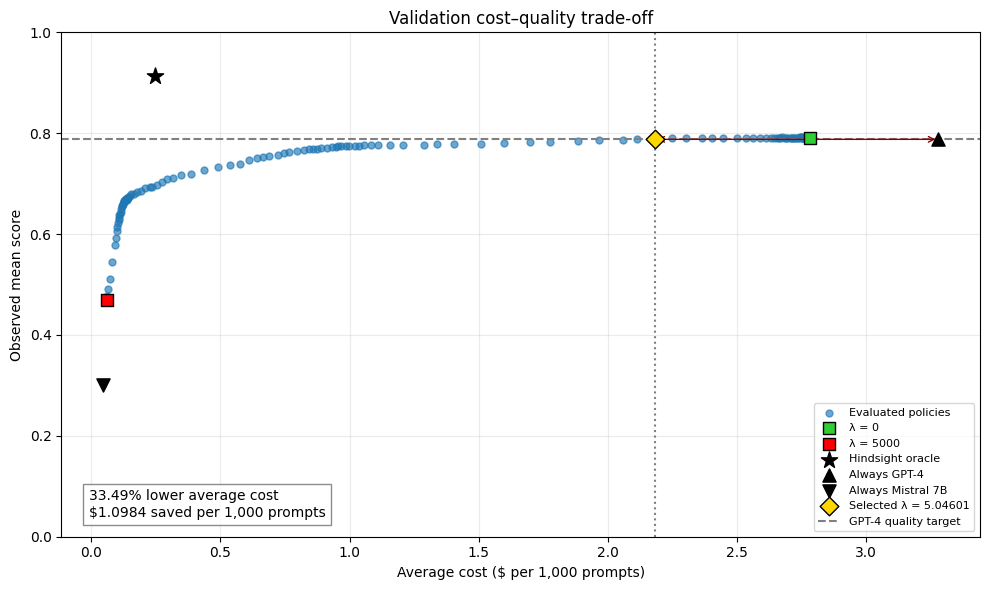

In [14]:
# the trade-off and selected policy’s savings

import matplotlib.pyplot as plt

curve = policy_results.sort_values("lambda")
zero_policy = curve.loc[curve["lambda"].eq(0)].iloc[0]
last_policy = curve.iloc[-1]

gpt4_cost = 1000 * validation_costs[REFERENCE_MODEL].mean()
gpt4_score = validation_scores[REFERENCE_MODEL].mean()

mistral_name = "mistralai/mistral-7b-chat"

selected_cost = 1000 * best_policy["mean_cost_dollars"]
selected_score = best_policy["observed_mean_score"]

points = {
    "λ = 0": (
        1000 * zero_policy["mean_cost_dollars"],
        zero_policy["observed_mean_score"],
        "s", "limegreen", 70,
    ),
    f"λ = {last_policy['lambda']:g}": (
        1000 * last_policy["mean_cost_dollars"],
        last_policy["observed_mean_score"],
        "s", "red", 70,
    ),
    "Hindsight oracle": (
        1000 * oracle_cost, oracle_score,
        "*", "black", 150,
    ),
    "Always GPT-4": (
        gpt4_cost, gpt4_score,
        "^", "black", 90,
    ),
    "Always Mistral 7B": (
        1000 * validation_costs[mistral_name].mean(),
        validation_scores[mistral_name].mean(),
        "v", "black", 90,
    ),
    f"Selected λ = {best_lambda:.6g}": (
        selected_cost, selected_score,
        "D", "gold", 90,
    ),
}

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    1000 * curve["mean_cost_dollars"],
    curve["observed_mean_score"],
    s=25,
    alpha=0.65,
    label="Evaluated policies",
)

for label, (cost, score, marker, color, size) in points.items():
    ax.scatter(
        cost, score,
        marker=marker,
        color=color,
        edgecolor="black",
        s=size,
        label=label,
        zorder=4,
    )

ax.axhline(
    tau,
    color="gray",
    linestyle="--",
    label="GPT-4 quality target",
)

ax.axvline(selected_cost, color="gray", linestyle=":")

ax.annotate(
    "",
    xy=(selected_cost, tau),
    xytext=(gpt4_cost, tau),
    arrowprops={"arrowstyle": "<->", "color": "darkred"},
)

ax.text(
    0.03, 0.04,
    f"{best_policy['cost_savings_pct']:.2f}% lower average cost\n"
    f"${best_policy['savings_per_1000_prompts']:.4f} saved per 1,000 prompts",
    transform=ax.transAxes,
    bbox={
        "facecolor": "white",
        "edgecolor": "gray",
        "alpha": 0.9,
    },
)

ax.set(
    title="Validation cost–quality trade-off",
    xlabel="Average cost ($ per 1,000 prompts)",
    ylabel="Observed mean score",
    ylim=(0, 1),
)

ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()